In [1]:
from google.colab import userdata

token = userdata.get("KAGGLE_API_TOKEN")
print("Kaggle token found:", bool(token))

Kaggle token found: True


In [2]:
!pip -q install kaggle

In [3]:
import os
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

!kaggle --version

Kaggle CLI 2.0.2


In [4]:
!kaggle competitions files -c airbus-ship-detection

Next Page Token = CfDJ8LXGgraiXMNClPzcySXY5U6y4Lun3YgjqCD4Zm_nww9evK7UBl7kCv5J6b0qeIJ_efPEYxBItdO7VwxrSOGMGEzALJJKT8UnFBfVgvh5fqKy_dRV-m2zPdji__E2Jakfk7tfdKFHD3AhmxGmxA
name                            size  creationDate                
------------------------  ----------  --------------------------  
sample_submission_v2.csv      280930  2019-12-15 22:22:19.017000  
test_v2/00002bd58.jpg         130641  2019-12-15 22:23:24.382000  
test_v2/00015efb6.jpg         150154  2019-12-15 22:23:37.881000  
test_v2/00023d5fc.jpg         147670  2019-12-15 22:23:37.818000  
test_v2/000367c13.jpg         164497  2019-12-15 22:23:08.279000  
test_v2/0008ca6e9.jpg         118279  2019-12-15 22:23:25.372000  
test_v2/000a4635f.jpg         193771  2019-12-15 22:23:37.890000  
test_v2/000bd9dbf.jpg         166488  2019-12-15 22:23:40.297000  
test_v2/000f7d875.jpg         138286  2019-12-15 22:23:06.390000  
test_v2/0010551d9.jpg         110146  2019-12-15 22:23:12.521000  
test_v2/001839c6f.jpg      

In [5]:
!mkdir -p /content/airbus_data
!kaggle competitions download \
  -c airbus-ship-detection \
  -f train_ship_segmentations_v2.csv \
  -p /content/airbus_data

100% 17.9M/17.9M [00:00<00:00, 76.9MB/s]



In [6]:
import os

print(os.listdir("/content/airbus_data"))

['train_ship_segmentations_v2.csv.zip']


In [7]:
import zipfile
import os

zip_path = "/content/airbus_data/train_ship_segmentations_v2.csv.zip"
extract_path = "/content/airbus_data"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extracted files:", os.listdir(extract_path))

Extracted files: ['train_ship_segmentations_v2.csv.zip', 'train_ship_segmentations_v2.csv']


In [8]:
import pandas as pd

csv_path = "/content/airbus_data/train_ship_segmentations_v2.csv"
df = pd.read_csv(csv_path)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (231723, 2)
Columns: ['ImageId', 'EncodedPixels']

First 5 rows:


,ImageId,EncodedPixels
0,00003e153.jpg,NaN
1,0001124c7.jpg,NaN
2,000155de5.jpg,264661 17 265429 33 266197 33 266965 33 267733...
3,000194a2d.jpg,360486 1 361252 4 362019 5 362785 8 363552 10 ...
4,000194a2d.jpg,51834 9 52602 9 53370 9 54138 9 54906 9 55674 ...


In [9]:
import pandas as pd

df = pd.read_csv(
    "/content/airbus_data/train_ship_segmentations_v2.csv"
)

labels = (
    df.assign(has_ship=df["EncodedPixels"].notna().astype(int))
      .groupby("ImageId")["has_ship"]
      .max()
)

print("Total unique images:", len(labels))
print("\nImage counts:")
print(labels.value_counts().rename(index={0: "No Ship", 1: "Ship"}))

Total unique images: 192556

Image counts:
has_ship
No Ship    150000
Ship        42556
Name: count, dtype: int64


In [17]:
!kaggle competitions download \
  -c airbus-ship-detection \
  -p /content/airbus_data

Resuming from 1428160512 bytes (29262350234 bytes left)...
100% 28.6G/28.6G [04:52<00:00, 99.9MB/s]



In [20]:
!ls -lh /content/airbus_data

total 29G
-rw-r--r-- 1 root root 29G Dec 16  2019 airbus-ship-detection.zip
-rw-r--r-- 1 root root 44M Oct  8 17:00 train_ship_segmentations_v2.csv
-rw-r--r-- 1 root root 18M Dec 15  2019 train_ship_segmentations_v2.csv.zip


In [21]:
import shutil

total, used, free = shutil.disk_usage("/content")

print(f"Free storage before extraction: {free / (1024**3):.2f} GB")

Free storage before extraction: 41.64 GB


checking the remanining storage before extracting the 29GB archive

In [22]:
import zipfile

zip_path = "/content/airbus_data/airbus-ship-detection.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    total_size = sum(item.file_size for item in z.infolist())
    print(f"Extracted size: {total_size / (1024**3):.2f} GB")

Extracted size: 29.25 GB


In [24]:
import zipfile
from collections import Counter

zip_path = "/content/airbus_data/airbus-ship-detection.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    files = z.infolist()
    counts = Counter(
        name.split("/")[0]
        for name in (f.filename for f in files)
    )

    print("Total files:", len(files))
    print("\nFile groups:")
    for name, count in counts.items():
        print(name, ":", count, "files")

Total files: 208164

File groups:
sample_submission_v2.csv : 1 files
test_v2 : 15606 files
train_ship_segmentations_v2.csv : 1 files
train_v2 : 192556 files


In [25]:
import os
import zipfile
from collections import defaultdict

zip_path = "/content/airbus_data/airbus-ship-detection.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    sizes = defaultdict(int)

    for item in z.infolist():
        group = item.filename.split("/")[0]
        sizes[group] += item.file_size

    print("Uncompressed sizes:")
    for group, size in sizes.items():
        print(f"{group}: {size / (1024**3):.2f} GB")

    total = sum(item.file_size for item in z.infolist())
    print(f"\nTOTAL uncompressed: {total / (1024**3):.2f} GB")

free = shutil.disk_usage("/content").free / (1024**3)
print(f"Free Colab storage: {free:.2f} GB")

Uncompressed sizes:
sample_submission_v2.csv: 0.00 GB
test_v2: 2.18 GB
train_ship_segmentations_v2.csv: 0.04 GB
train_v2: 27.03 GB

TOTAL uncompressed: 29.25 GB
Free Colab storage: 41.64 GB


checking disk space before extracting

# extracting the datasets

In [ ]:
import zipfile
import os

zip_path = "/content/airbus_data/airbus-ship-detection.zip"
extract_path = "/content/airbus_data/full_dataset"

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

print("Extraction completed!")
print("Dataset folders:", os.listdir(extract_path))

in cell 29 ,did not run this code completely because of not enough disk space, so we were able to extract only 151881 training images and all 15606 test images,out of total 208164 images

In [30]:
import os
import pandas as pd

folder = "/content/airbus_data/full_dataset/train_v2"
csv_path = "/content/airbus_data/train_ship_segmentations_v2.csv"

# Get extracted image filenames
images = set(os.listdir(folder))

# Read CSV and create one label per image
df = pd.read_csv(csv_path)
labels = df.groupby("ImageId")["EncodedPixels"].apply(
    lambda x: x.notna().any()
)

# Count ships and non-ships among available images
matched = labels[labels.index.isin(images)]

print("Extracted images:", len(images))
print("Images matched with labels:", len(matched))
print("Images WITH ships:", int(matched.sum()))
print("Images WITHOUT ships:", int((~matched).sum()))
print("Images without matching labels:", len(images) - len(matched))

Extracted images: 151881
Images matched with labels: 151881
Images WITH ships: 33535
Images WITHOUT ships: 118346
Images without matching labels: 0


will be preparing a balanced subset of 20000 images with 10000 with ship and 10000 withtout ships with the images we already have
We'll select 10,000 images with ships and 10,000 without ships, then split them into training, validation, and test sets.
NOTE:we are not using the complete dataset, we are only using the subset of it because of restricted disk space

# PREPARING DATASET

In [33]:
import os
import pandas as pd
import numpy as np

# Dataset paths
IMAGE_DIR = "/content/airbus_data/full_dataset/train_v2"
CSV_PATH = "/content/airbus_data/train_ship_segmentations_v2.csv"

# Read the CSV containing ship segmentation labels
df = pd.read_csv(CSV_PATH)

# Create one binary label per image
labels = (
    df.assign(has_ship=df["EncodedPixels"].notna().astype(int))
      .groupby("ImageId")["has_ship"]
      .max()
      .reset_index()
)

# Keep only images that actually exist
available_images = set(os.listdir(IMAGE_DIR))
labels = labels[labels["ImageId"].isin(available_images)]

print("Available labeled images:", len(labels))
print("\nClass distribution:")
print(labels["has_ship"].value_counts().rename({
    0: "No ship",
    1: "Ship"
}))

Available labeled images: 151881

Class distribution:
has_ship
No ship    118346
Ship        33535
Name: count, dtype: int64


cell 34, selecting 20000 balanced images

In [34]:
# Select 10,000 images from each class
ship_images = labels[labels["has_ship"] == 1].sample(
    n=10000, random_state=42
)

no_ship_images = labels[labels["has_ship"] == 0].sample(
    n=10000, random_state=42
)

# Combine and shuffle
dataset = pd.concat(
    [ship_images, no_ship_images],
    ignore_index=True
).sample(frac=1, random_state=42).reset_index(drop=True)

print("Total selected images:", len(dataset))
print("\nSelected class distribution:")
print(dataset["has_ship"].value_counts().rename({
    0: "No ship",
    1: "Ship"
}))

# Save the selected image list
dataset.to_csv(
    "/content/airbus_data/selected_dataset.csv",
    index=False
)

print("\nDataset selection saved!")

Total selected images: 20000

Selected class distribution:
has_ship
No ship    10000
Ship       10000
Name: count, dtype: int64

Dataset selection saved!


now , we split the dataset as

70% for training — 14,000 images
15% for validation — 3,000 images
15% for testing — 3,000 images

In [35]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    dataset,
    test_size=0.30,
    stratify=dataset["has_ship"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["has_ship"],
    random_state=42
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

# Save the splits
train_df.to_csv("/content/airbus_data/train.csv", index=False)
val_df.to_csv("/content/airbus_data/validation.csv", index=False)
test_df.to_csv("/content/airbus_data/test.csv", index=False)

print("\nAll three splits saved successfully!")

Training images: 14000
Validation images: 3000
Testing images: 3000

All three splits saved successfully!


# Load and resize the images

cell 36,Now we'll prepare the images for the CNN. Our original images are large, so we'll resize them to 128 × 128 pixels to make training more manageable on your Colab T4 GPU.

In [36]:
import os
import pandas as pd

base = "/content/airbus_data"
image_dir = "/content/airbus_data/full_dataset/train_v2"

for filename in ["train.csv", "validation.csv", "test.csv"]:
    df = pd.read_csv(os.path.join(base, filename))

    missing = sum(
        not os.path.isfile(os.path.join(image_dir, img))
        for img in df["ImageId"]
    )

    print(
        f"{filename}: {len(df)} images | "
        f"Missing image files: {missing}"
    )

train.csv: 14000 images | Missing image files: 0
validation.csv: 3000 images | Missing image files: 0
test.csv: 3000 images | Missing image files: 0


# Create the image-loading pipeline

Instead of loading all 20,000 images into memory at once, we'll use a batch-based pipeline. This is more memory-efficient and works well with your T4 GPU.

**4.1 Install and import the required libraries**

In [37]:
import tensorflow as tf
import pandas as pd
import os

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


**4.2 Defining our image settings**

In [38]:
IMAGE_DIR = "/content/airbus_data/full_dataset/train_v2"
BASE_DIR = "/content/airbus_data"

IMG_SIZE = 128
BATCH_SIZE = 32

train_df = pd.read_csv(os.path.join(BASE_DIR, "train.csv"))
val_df = pd.read_csv(os.path.join(BASE_DIR, "validation.csv"))
test_df = pd.read_csv(os.path.join(BASE_DIR, "test.csv"))

print("Image size:", IMG_SIZE, "x", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Image size: 128 x 128
Batch size: 32
Training: 14000
Validation: 3000
Testing: 3000


**4.3 Build the data pipeline**
This reads each image when needed, resizes it, and scales its pixel values from 0–255 to 0–1.

In [39]:
AUTOTUNE = tf.data.AUTOTUNE

def load_image(image_name, label):
    image_path = tf.strings.join(
        [IMAGE_DIR, "/", image_name]
    )

    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32) / 255.0

    label = tf.cast(label, tf.float32)

    return image, label


def create_dataset(dataframe, training=False):
    image_names = dataframe["ImageId"].values
    labels = dataframe["has_ship"].values.astype("float32")

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_names, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=2000,
            seed=42
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("Image pipelines created successfully!")

Image pipelines created successfully!


**Test one batch**

Before building the CNN, let's confirm the images load correctly.

In [40]:
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())
    print("Labels in this batch:", labels.numpy())

Image batch shape: (32, 128, 128, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Labels in this batch: [0. 1. 1. 0. 0. 0. 1. 1. 0. 0. 0. 0. 1. 0. 1. 1. 1. 1. 1. 0. 1. 0. 0. 1.
 1. 0. 0. 1. 1. 0. 0. 1.]


# **BUILDING THE CNN MODEL**
Our CNN will learn visual patterns such as ship shapes, edges, and textures to classify each image into Ship or No Ship.

In [41]:
from tensorflow.keras import layers, models

model = models.Sequential([
    # Input layer
    layers.Input(shape=(128, 128, 3)),

    # Convolution block 1
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution block 2
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution block 3
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,569 (396.75 KB)

 Trainable params: 101,569 (396.75 KB)

 Non-trainable params: 0 (0.00 B)

**Step 7 — Train the CNN**
We'll train for up to 10 epochs and stop early if validation loss stops improving.

In [42]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "/content/airbus_best_model.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.5711 - loss: 0.6707 - precision: 0.5732 - recall: 0.4664
Epoch 1: val_loss improved from None to 0.58766, saving model to /content/airbus_best_model.keras

Epoch 1: finished saving model to /content/airbus_best_model.keras
438/438 ━━━━━━━━━━━━━━━━━━━━ 87s 170ms/step - accuracy: 0.6356 - loss: 0.6341 - precision: 0.6423 - recall: 0.6123 - val_accuracy: 0.7060 - val_loss: 0.5877 - val_precision: 0.7198 - val_recall: 0.6747
Epoch 2/10
437/438 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 0.7055 - loss: 0.5836 - precision: 0.7000 - recall: 0.7012
Epoch 2: val_loss improved from 0.58766 to 0.52359, saving model to /content/airbus_best_model.keras

Epoch 2: finished saving model to /content/airbus_best_model.keras
438/438 ━━━━━━━━━━━━━━━━━━━━ 49s 112ms/step - accuracy: 0.7188 - loss: 0.5690 - precision: 0.7142 - recall: 0.7296 - val_accuracy: 0.7490 - val_loss: 0.5236 - val_precision: 0.7628 - val_recall: 0.7227
Epoch 3/10
4

cell 48-51,saving the cnn model to save the progress of it

In [48]:
model.save("/content/airbus_best_model.keras")
print("Model saved in temporary storage!")

Model saved in temporary storage!


In [49]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [50]:
import os

save_path = "/content/drive/MyDrive/airbus_best_model.keras"

model.save(save_path)

print("Model saved successfully:", os.path.exists(save_path))
print("Model size:", round(os.path.getsize(save_path) / (1024**2), 2), "MB")

Model saved successfully: True
Model size: 1.21 MB


In [51]:
import os

path = "/content/drive/MyDrive/airbus_best_model.keras"

if os.path.exists(path):
    print("✅ Your trained CNN is safely saved in Google Drive!")
else:
    print("❌ Model file not found. Tell me what happened.")

✅ Your trained CNN is safely saved in Google Drive!


# EVALUATING THE CNN ON THE TEST DATASET

In [52]:
test_results = model.evaluate(test_ds, verbose=1)

print("\n===== CNN TEST RESULTS =====")
for name, value in zip(model.metrics_names, test_results):
    print(f"{name}: {value:.4f}")

94/94 ━━━━━━━━━━━━━━━━━━━━ 14s 144ms/step - accuracy: 0.8817 - loss: 0.2991 - precision: 0.8764 - recall: 0.8887

===== CNN TEST RESULTS =====
loss: 0.2991
compile_metrics: 0.8817


cell 54,
Calculating F1 score after evaluating

In [54]:
from sklearn.metrics import f1_score

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy().astype(int))
    y_pred.extend((predictions.ravel() >= 0.5).astype(int))

f1 = f1_score(y_true, y_pred)

print(f"Test F1-score: {f1:.4f}")

Test F1-score: 0.8825


cell 56,**Generate the classification report and confusion matrix**

These will help us understand exactly where our CNN makes mistakes.


              precision    recall  f1-score   support

     No Ship     0.8871    0.8747    0.8808      1500
        Ship     0.8764    0.8887    0.8825      1500

    accuracy                         0.8817      3000
   macro avg     0.8817    0.8817    0.8817      3000
weighted avg     0.8817    0.8817    0.8817      3000



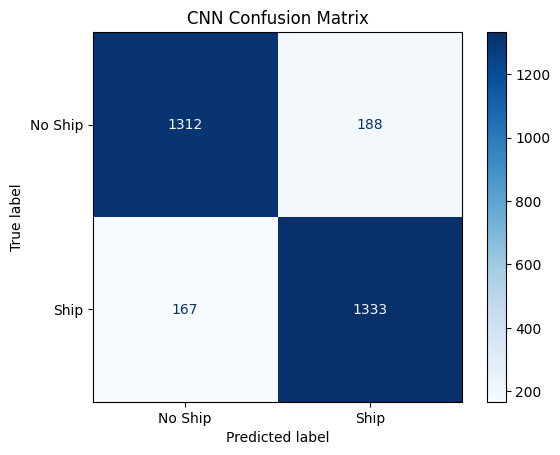

In [55]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Generate predictions on the test set
y_true = []
y_pred = []

for images, labels in test_ds:
    probabilities = model.predict(images, verbose=0).ravel()
    y_true.extend(labels.numpy().astype(int))
    y_pred.extend((probabilities >= 0.5).astype(int))

# Classification report
print(classification_report(
    y_true,
    y_pred,
    target_names=["No Ship", "Ship"],
    digits=4
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Ship", "Ship"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("CNN Confusion Matrix")
plt.show()

cell 57,**Plot training and validation graphs**

show how the model learned over time.

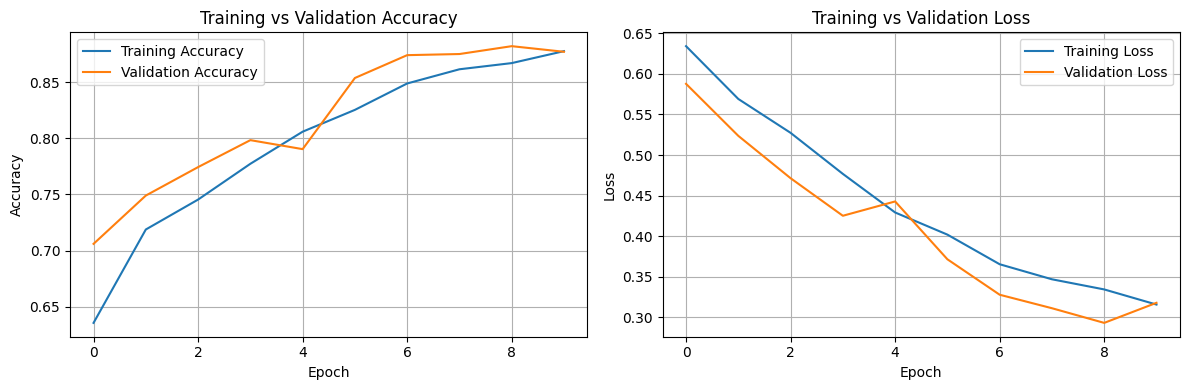

In [56]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig(
    "/content/drive/MyDrive/airbus_training_graphs.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

**Generate the confusion matrix and classification report**

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

     No Ship     0.8871    0.8747    0.8808      1500
        Ship     0.8764    0.8887    0.8825      1500

    accuracy                         0.8817      3000
   macro avg     0.8817    0.8817    0.8817      3000
weighted avg     0.8817    0.8817    0.8817      3000



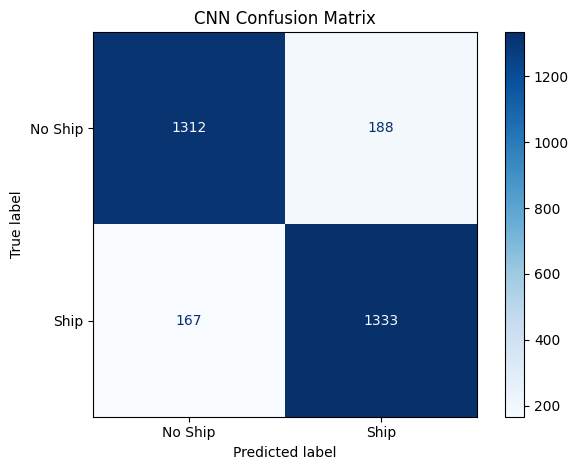

In [57]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

y_true = []
y_pred = []

for images, labels in test_ds:
    probabilities = model.predict(images, verbose=0).ravel()
    y_true.extend(labels.numpy().astype(int))
    y_pred.extend((probabilities >= 0.5).astype(int))

print("===== CLASSIFICATION REPORT =====")
print(classification_report(
    y_true,
    y_pred,
    target_names=["No Ship", "Ship"],
    digits=4
))

cm = confusion_matrix(y_true, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Ship", "Ship"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("CNN Confusion Matrix")
plt.tight_layout()
plt.savefig(
    "/content/drive/MyDrive/airbus_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

saving all the outputs

In [58]:

import os

print("===== PROJECT OUTPUTS =====")

files = [
    "/content/drive/MyDrive/airbus_best_model.keras",
    "/content/drive/MyDrive/airbus_training_graphs.png",
    "/content/drive/MyDrive/airbus_confusion_matrix.png"
]

for path in files:
    print(
        os.path.basename(path),
        "— SAVED" if os.path.exists(path) else "— NOT FOUND"
    )

===== PROJECT OUTPUTS =====
airbus_best_model.keras — SAVED
airbus_training_graphs.png — SAVED
airbus_confusion_matrix.png — SAVED


cell 60,final results table is being saved to drive

In [60]:

from IPython.display import display as show_table
import pandas as pd

save_path = "/content/drive/MyDrive/airbus_final_results.csv"

results = pd.read_csv(save_path)
show_table(results)

,Metric,Result
0,Test Images,3000
1,Test Accuracy,88.17%
2,Precision,87.64%
3,Recall,88.87%
4,F1-Score,88.25%
5,Test Loss,0.2991
6,Image Size,128 x 128 pixels
7,Classes,Ship / No Ship
